# Introducrtion to Machine Learning: Assignment #1
## Submission date: 29\04\2026, 23:59.
### Topics:
- Parametric Density Estimation
- Bayesian Decision Rule
- Linear regression


Submitted by:

 Rawa Abu Salah ID:325143634

 Reema khalaily ID:214281479

**Assignment Instruction:**

· Submissions in pairs only.

· Try to keep the code as clean, concise, and short as possible

· If you wish to work in your IDE, you can, but you **must**,  insert the script back to the matching cells of the notebook and run the code. <br/>Only the notebook will be submitted in moodle (in `.ipynb` format).

· <font color='red'>Please write your answers to question in red</font>.

**Important:** All plots, results and outputs should be included in the notebook as the cells' outputs (run all cells and do not clear the output). <br/>

**Important:** Your submission must be entirely your own. Any attempts of plagiarism (including ChatGPT) will lead to grade 0 and disciplinary actions.

## Question 1 - Parametric Estimation and MAP

**Make sure to provide full solutions here.**

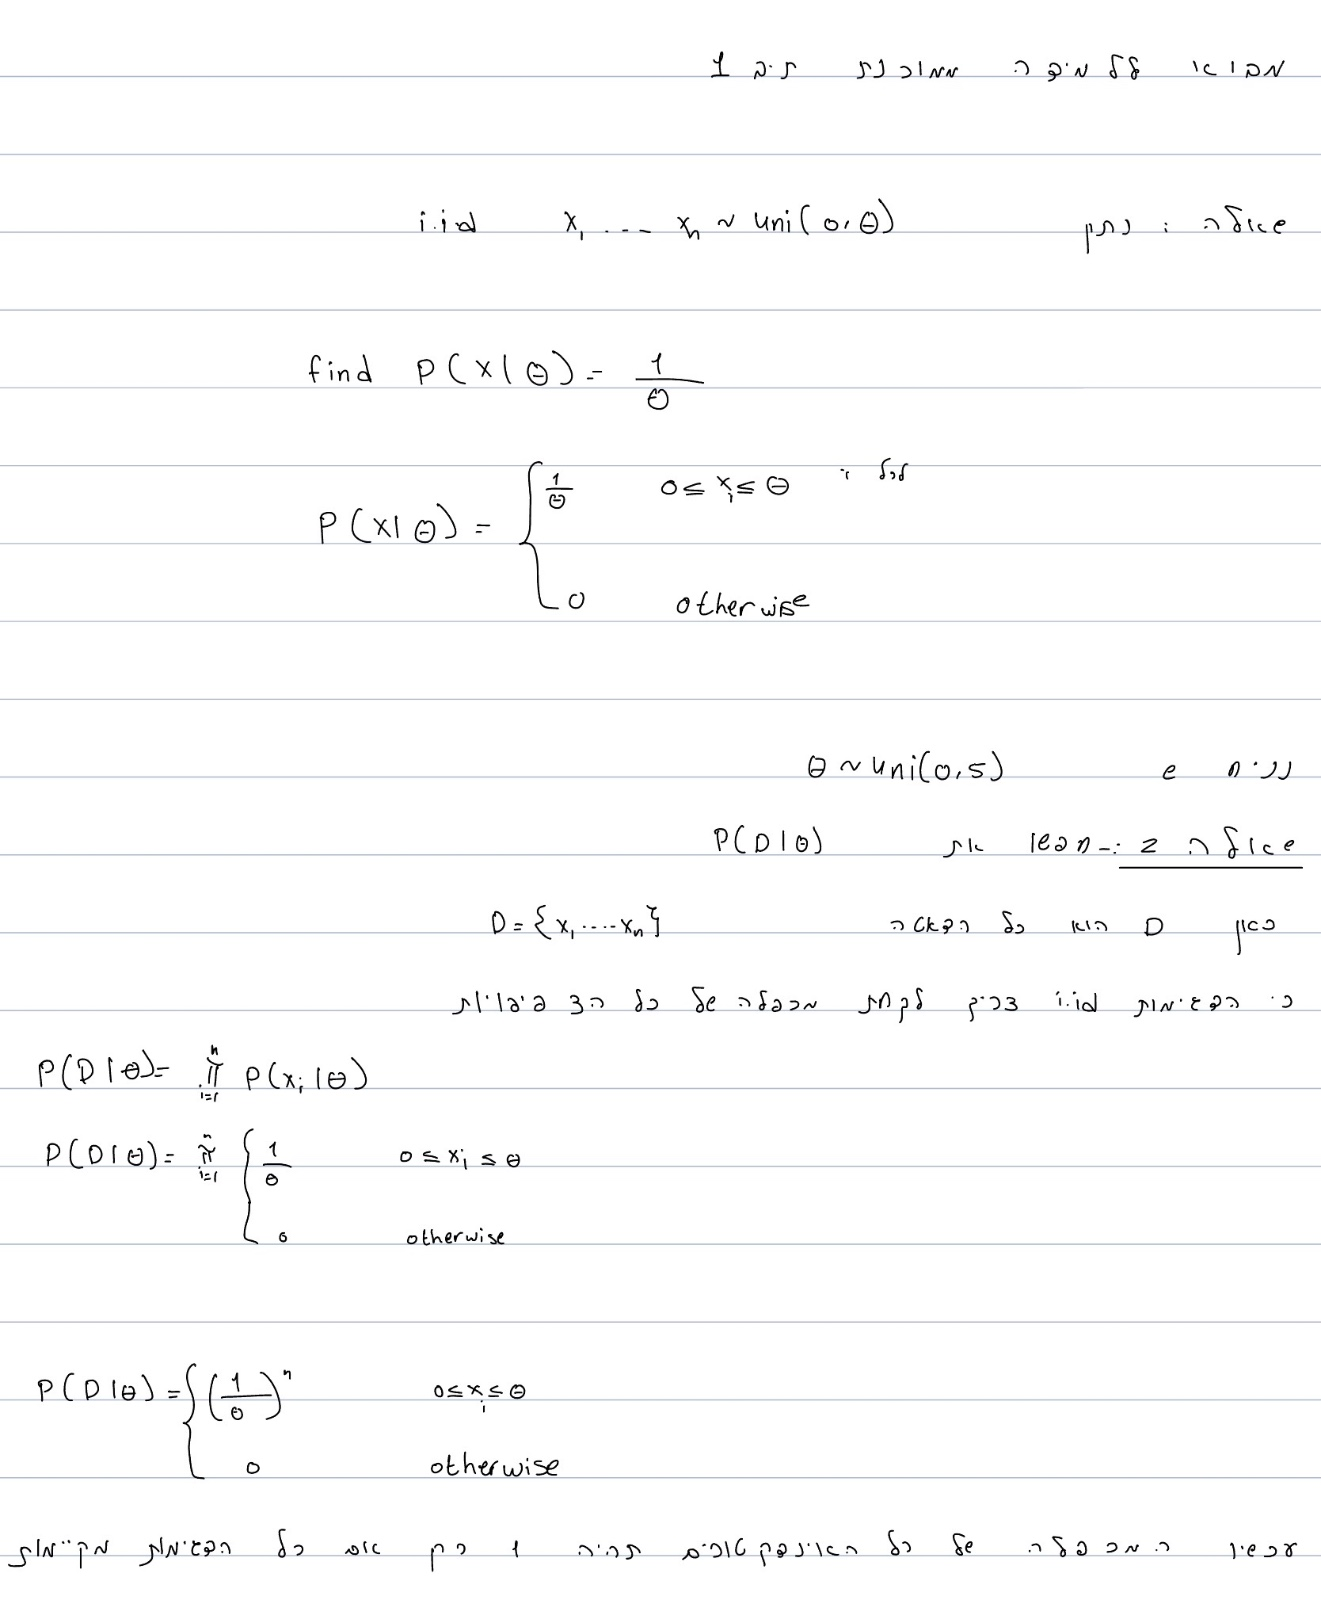

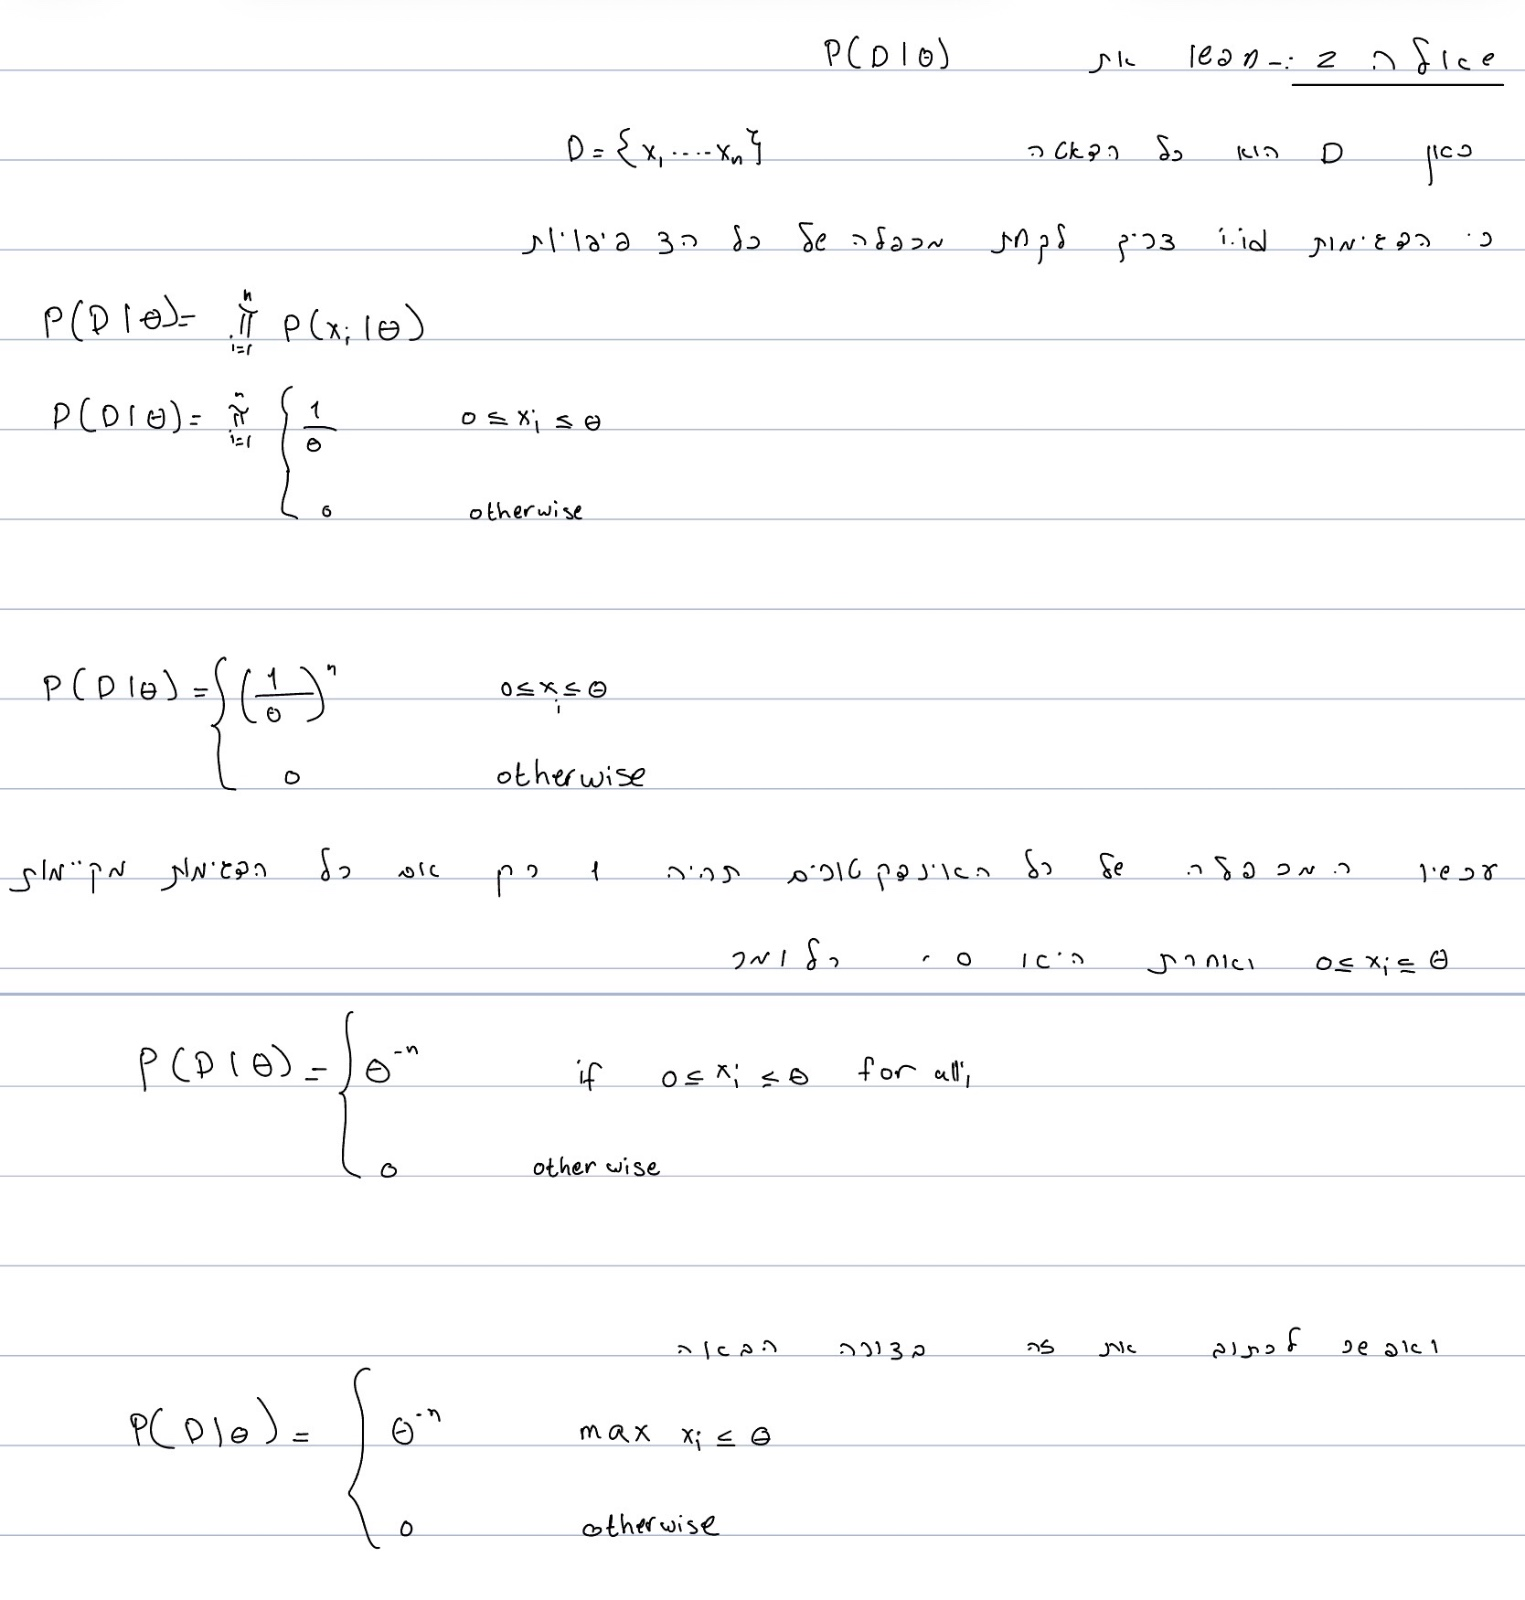

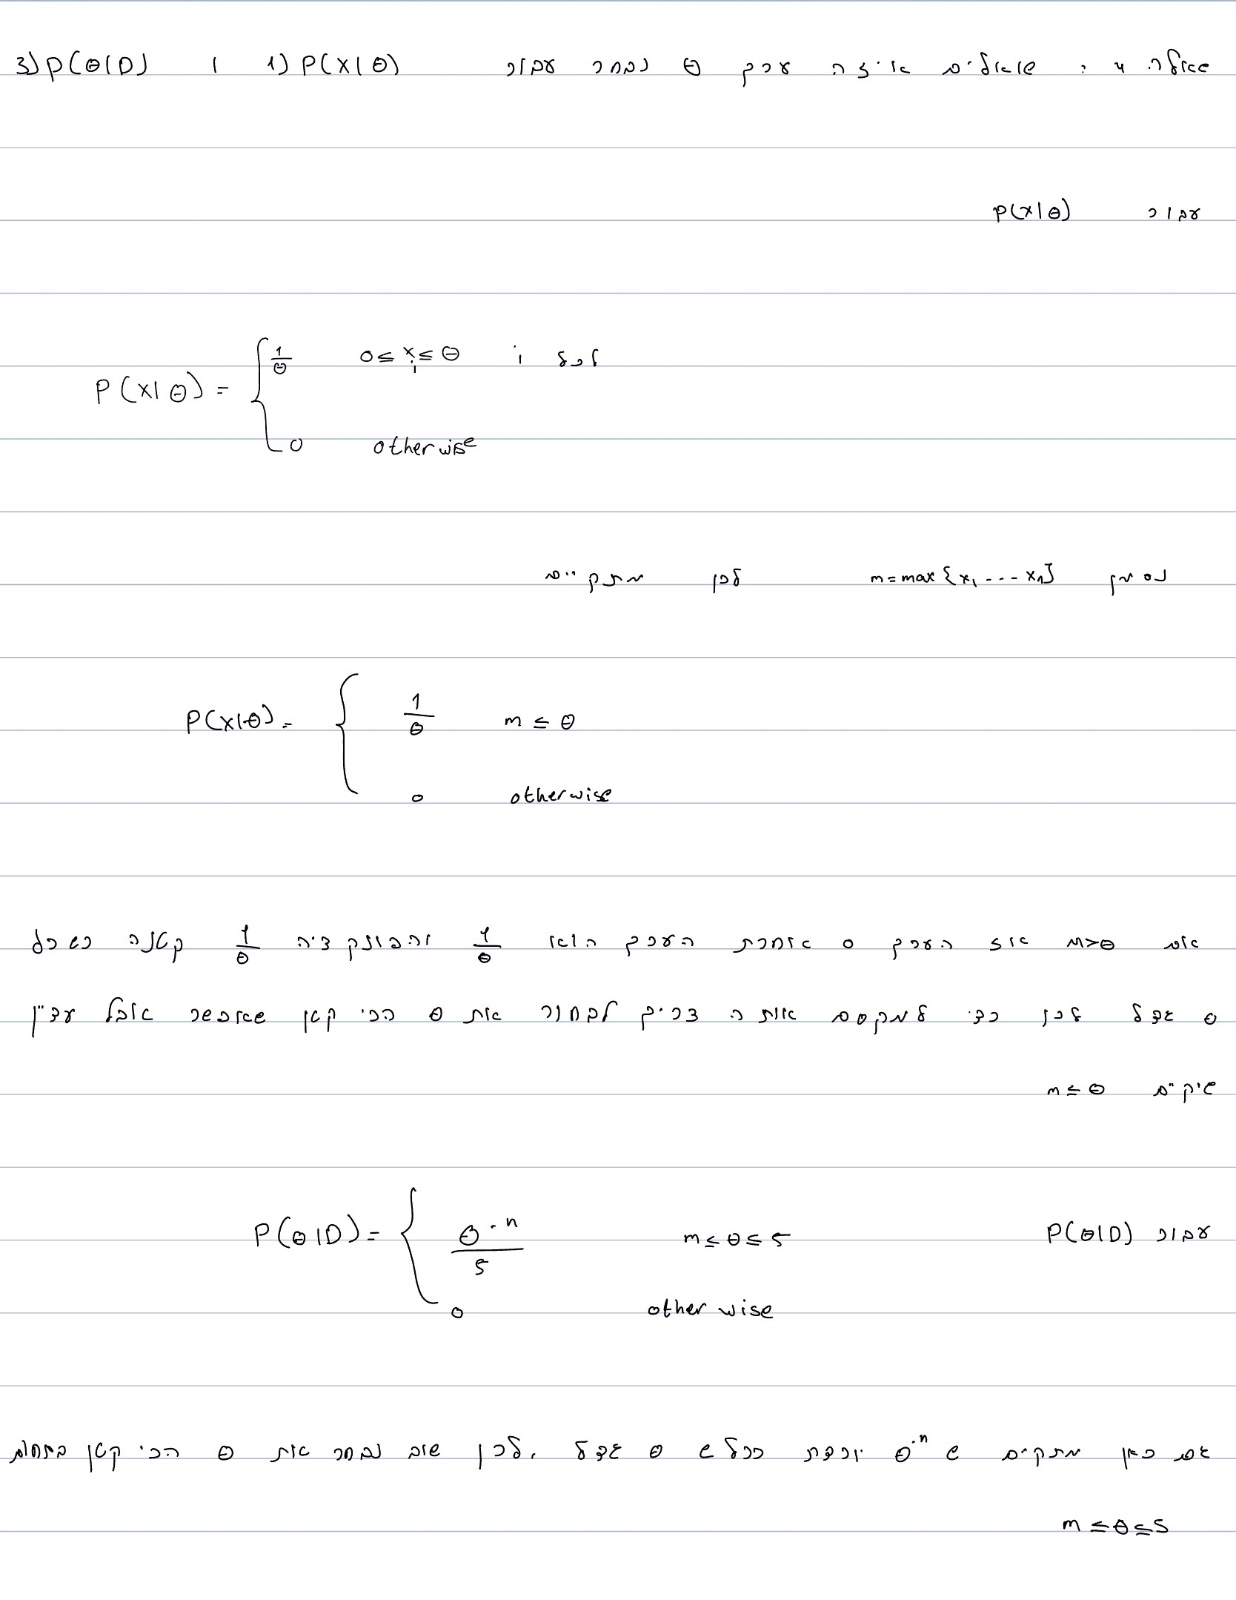

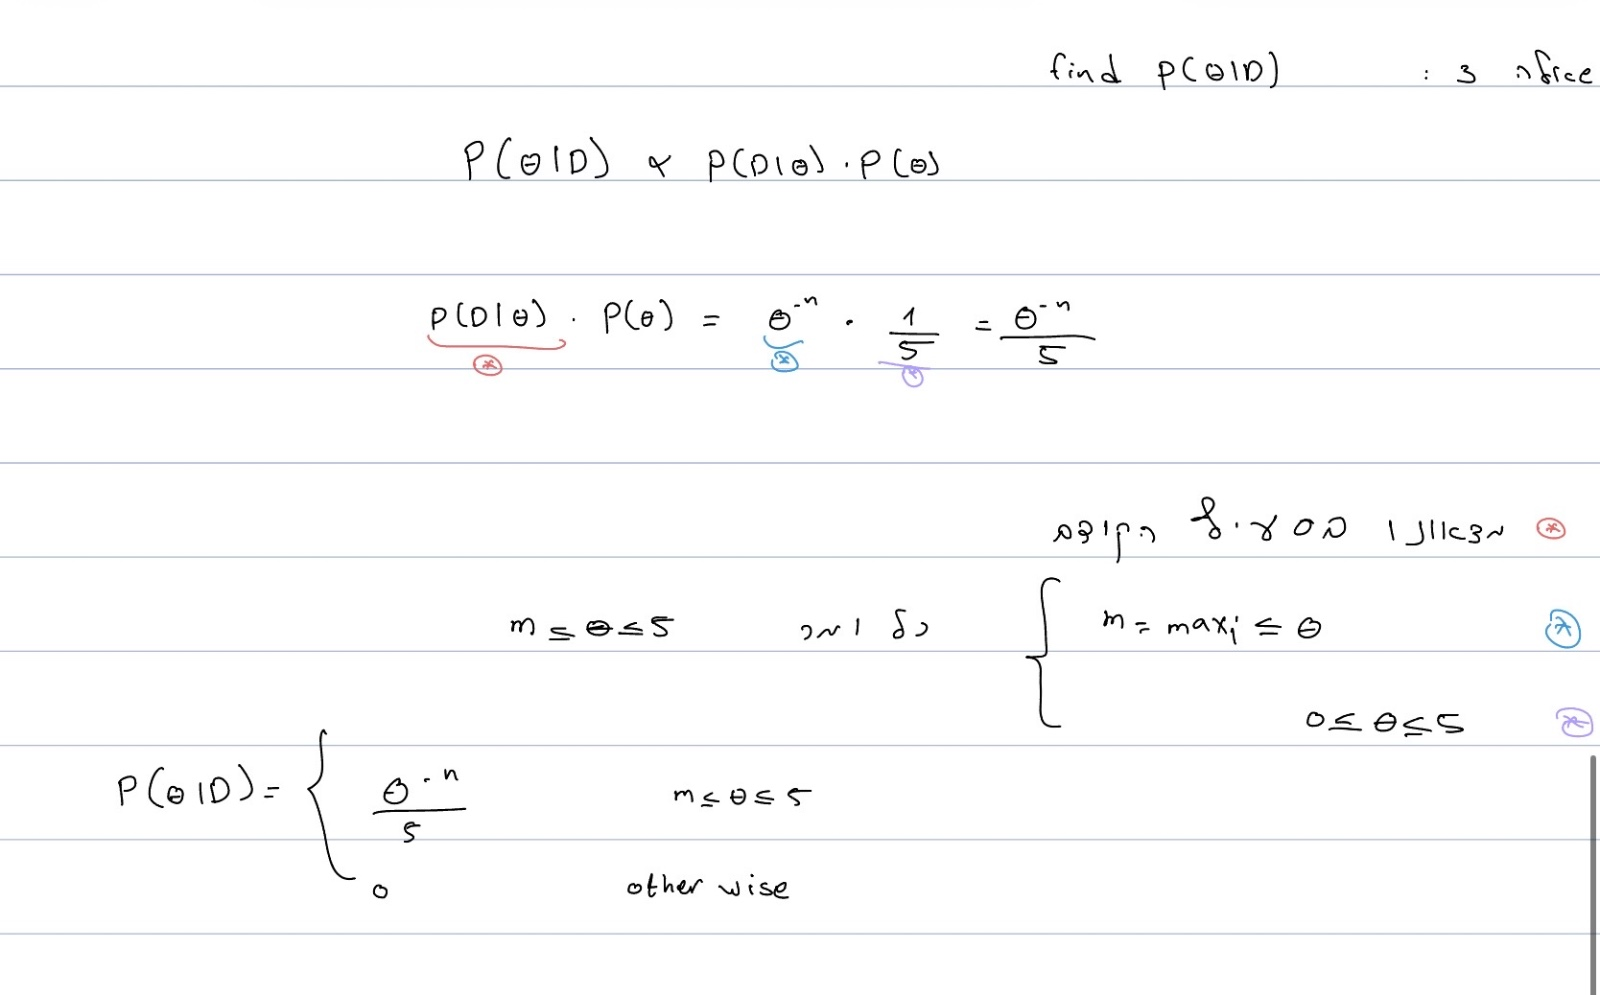

In this problem, you are given n i.i.d samples $x_1,...,x_n\sim \mathcal{U}(0,\theta)$.

In this question, we aim to construct the distribution from samples, and comparing both MLE vs MAP assumptions.

1. Find $p(x|\theta)$

Asssume $\theta\sim \mathcal{U}(0,5)$.

2. Find $p(D|\theta)$
3. Find $p(\theta|D)$

4. For both (1),(3), find which $\theta$ will be chosen

## Customizing Colab
This is an optional section for you convenience:<br/>
Go to Tools -> Settings -> editor<br/>
There, you can adjust fonts, add line numbers, change indentations.

## Question 2 - Linear regression
In this exercise you will implement linear regression alone!<br/>
The data consists of Marks of students including their study time & number of courses. We aim to predict their marks. <br/>
Dataset is here: https://sharon.srworkspace.com/ml/datasets/hw1/Student_Marks.csv

The dataset consists of a few 2-feature samples $\{(x_i,y_i )\}_{i=1}^∞$ where $y_i$ is the prediction of the $x_i\in\mathbb{R}^2$ sample. <br/>
We will only try to fit the given data, <u>without validation or test</u>.<br/>
We define the following:
-	X, 2d matrix from size n x d which represents the training samples.
-	y, array from size n which represents the target value for the corresponding sample.


import libarires

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Load and visualize the data

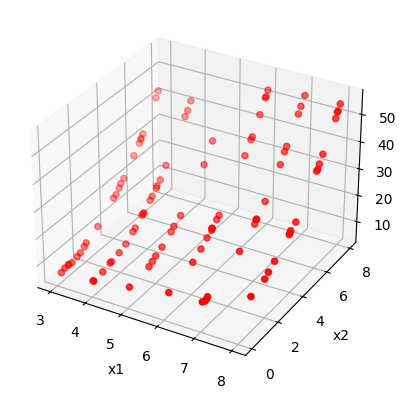

In [50]:
def get_data():
    df =pd.read_csv("https://sharon.srworkspace.com/ml/datasets/hw1/Student_Marks.csv")
    return df.iloc[:, :-1].values, df.iloc[:, -1].values

X, y = get_data()
# visualize
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:,0], X[:,1], y, color='red')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('y')
plt.show()

Now, plot the correlation matrix between the two features. <br/>
Should linear regression help?

In [51]:
df = pd.read_csv("https://sharon.srworkspace.com/ml/datasets/hw1/Student_Marks.csv")
print(df.corr())

                number_courses  time_study     Marks
number_courses        1.000000    0.204844  0.417335
time_study            0.204844    1.000000  0.942254
Marks                 0.417335    0.942254  1.000000


<font color='red'>The linear regression helps because there is a high correlation 0.94 between study time and marks </font>

Implement the function Linreg_sol(X,y) which outputs the closed form solution for linear regression on X,y. <br/>

In [52]:
# X: (n,d) array
# y: (n,) array
# Output: (d,) array of weights

def Linreg_sol(X, y):
	return np.linalg.inv(X.T @ X) @ X.T @ y

Preprocess X and call the solver.<br/>
Afterwards, print the MSE (this will be the training error).

In [53]:
X, y = get_data()
X =  np.c_[X, np.ones(X.shape[0])]

w = Linreg_sol(X, y)
w1, w2, b = w

print(f'The linear line is y={w1:.2f}*x1+{w2:.2f}*x2+{b:.2f}')

y_pred = X @ w
mse = np.mean((y - y_pred) ** 2)
print(f'The MSE on the data is {mse:.2f}')

The linear line is y=1.86*x1+5.40*x2+-7.46
The MSE on the data is 12.12


Plot the line solution <br/>
Does the line really fit the data? <br/>
<font color='red'>Write here your answer and explain it</font>

 <font color='red'>The model in the result shows the pattern of the data, but it does not perfectly match every point, so there is some error.</font>

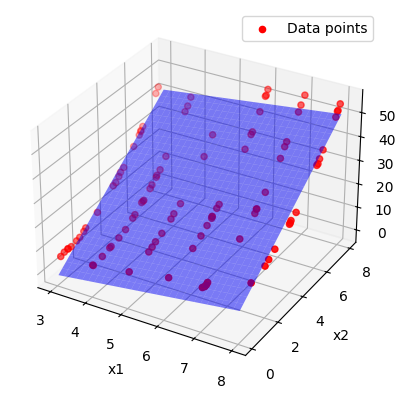

In [54]:
# Prepear a grid - many pairs of (x1,x2) to generate f(x1,x2) from
x1_range = np.linspace(X[:,0].min(), X[:,0].max(), 30)
x2_range = np.linspace(X[:,1].min(), X[:,1].max(), 30)
x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)
y_pred = w1 * x1_grid + w2 * x2_grid + b

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:,0], X[:,1], y, color='red', label='Data points')
ax.plot_surface(x1_grid, x2_grid, y_pred, color='blue', alpha=0.5)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('y')
ax.legend()
plt.show()

The above MSE should be much lower. Let's test a few techniques to deal with outliers and compare them.

The first technique is based upon the standard deviation:
$$ s=\sqrt{Var(SSE)}=\sqrt{\frac{\sum_{i=1}^n (y_i-f(x_i))^2}{n-1}} $$

Then, a point in the dataset defined as an outlier if its distance from the fitted line is more than two deviation s.<br/>
Find and print the outliers from the dataset.

In [55]:
X, y = get_data()

X = np.c_[X, np.ones(X.shape[0])]

y_pred = X @ w
errors = (y - y_pred) ** 2

s = np.sqrt(np.sum(errors) / (len(y) - 1))

outliers = np.abs(y - y_pred) > 2 * s

print("Number of outliers:", np.sum(outliers))

Number of outliers: 1


The second technique is based upon quantiles. <br/>
Run the following cell.
- The yellow line is the median
- The blue box shows the 25%-75% percentile
- The lowest and highest lines in black show the lowest and highest values of the feature.

/tmp/ipykernel_1203/3081240355.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, patch_artist=True)


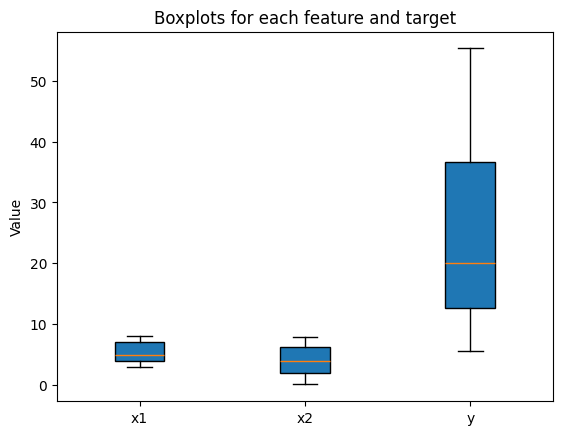

In [56]:
X, y = get_data()
data = [X[:,0], X[:,1], y]
labels = ['x1', 'x2', 'y']

plt.boxplot(data, labels=labels, patch_artist=True)
plt.title('Boxplots for each feature and target')
plt.ylabel('Value')
plt.show()

Now, remove the bad percentile (upon your choice) and print the MSE on the modified data. Explain the values you chose.

<font color='red'>Write here your answer and explain it</font>

In [57]:
low, high = np.percentile(y, [7, 94])    # replace l,h with your own values
mask = (y >= low) & (y <= high)
X_clean = X[mask]
y_clean = y[mask]
w_clean = Linreg_sol(X_clean, y_clean)
y_pred_clean = X_clean @ w_clean
mse_clean = np.mean((y_clean - y_pred_clean) ** 2)

print("MSE after cleaning:", mse_clean)

MSE after cleaning: 14.115179500933598


<font color='red'>I removed extreme values by using 7 and 94 and remove possible outliers. we notice that the MSE increased after this, it is meaning that some important data points were also removed. so we can infer that those values were not actual outliers, but rather was a normal data distribution.</font>

Answer the following sum-up questions:
1. Which method worked better? Why?
2. Could you conclude something in general?
3. What will happen to the MSE if you choose l,h such that they preserve very few points?
<font color='red'>Write here your answers and explain them</font>

<font color='red'>Answer for 1 :The standard deviation method worked better, because it find only one true outlier and saved most of the data. the percentile method removed more than one point, including useful ones, which will affected the model performance badly</font>

<font color='red'>Answer for 2 :In general, removing outliers can improve model performance, but only if the removed points are not appear frequently. Removing too many data points may remove useful information and harm the model </font>

<font color='red'>Answer for 3 :If we keep only a small number of data points, the model may learn them too much. This means it learns the specific data instead of the general pattern. As a result, it may work  on the training data but will not always work correctly on new unseen data </font>

## Question 3 - Bayesian Decision Rule

In this task you will train a classifier to determine animal based on its ear length, and use that to classify new samples. You are given a dataset containing 10k records of cats and dogs. <br/>The dataset is given here: https://sharon.srworkspace.com/ml/datasets/dataset2.csv

Import libraries

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

Use pandas module to load the dataset (directly from the url) into dataframe object.

Print the table size and print the first 5 rows.

In [59]:
df = pd.read_csv("https://sharon.srworkspace.com/ml/datasets/dataset2.csv")

print("table size:", df.shape)
print(df.head())

table size: (10000, 2)
   ear_length animal_type
0    5.656565         dog
1    5.368888         dog
2    3.707602         cat
3    5.377053         dog
4    3.796525         cat


As learned in the first tutorial, you should theoretically have a separate test set and craft a validation set from the data. However, we do not have such test and do not have any need from validation in this question.

Hence, like most of the course, you will generate the test directly from the given data:
1. Split the data to 80% training and 20% test with random state of 42.
2. Make sure to maintain the priors, using stratify=y, in train_test_split method. <br/>
  For example, if 60\% were cats, this will make sure that in both train and test will contain 60\% cats.

At the end, you should have two objects: `data_train`, `data_test`






In [60]:
from sklearn.model_selection import train_test_split

data_train, data_test = train_test_split( df, test_size=0.2,random_state=42, stratify=df['animal_type'])
print("Train size:", data_train.shape)
print("Test size:", data_test.shape)

Train size: (8000, 2)
Test size: (2000, 2)


Reminder: Bayesian classification takes a given sample x and chooses the class c maximizing:<br/><br/>
$$
\mathbb{P}(c|x)=\dfrac{\mathbb{P}(x|c)\cdot\mathbb{P}(c)}{\mathbb{P}(x)}
$$

Starting with prior, Implement the function `find_prior` and test it on both cats and dogs.



In [61]:
def find_prior(df, name):
    count = len(df[df['animal_type'] == name])
    total = len(df)
    return count / total

print(find_prior(data_train, 'dog'))
print(find_prior(data_train, 'cat'))

0.5
0.5


Now, looking at $\mathbb{P}(x|c)$, the distribution of ear length within c.<br/>Plot the train data and answer:
1. Only from the graph and intuitively, what will be the decision rule? In this case, the value of x which to the left you say "cat" and to the right you say "dog?

2. Say you answered x=c, and the prior is changed to be 80\% cats, 20\% dogs. Describe how the decision boundary will change.

3. What happens if we will not consider the priors, and only decide from the graph of likelihoods (p(x|c))?

<font color='red'>Write here your answers and explain them</font>

<font color='red'>Answer for 1:From the graph, the decision rule is around x = 4.5. If the ear length is smaller than 4.5 we classify it as cat, and if it is larger we classify it as dog.</font>.

<font color='red'>Answer for 2 :If the prior changes to 80% cats, the decision rule will move to the right. This is because the amont of the cats are bigger</font>

<font color='red'>Answer for 3 :If we ignore the priors, the decision rule will be where the two curves meet, but this can reduce accuracy because it does not consider how frequent each class is</font>

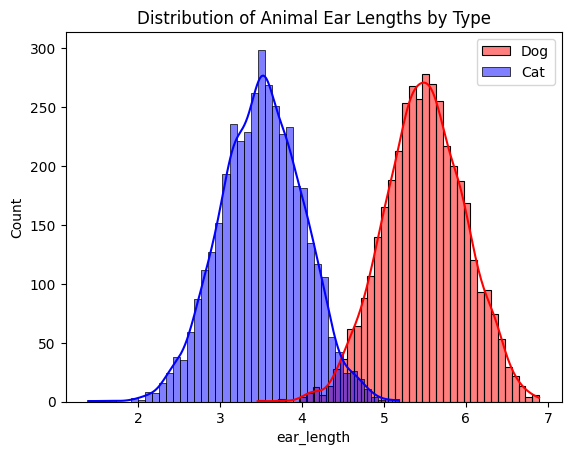

In [62]:
import seaborn as sns
def show_data(df):
    # Create a distribution plot using seaborn for each animal type
    sns.histplot(data=df[df.iloc[:, 1] == "dog"], x=df.columns[0], color="red", kde=True, alpha=0.5, label="Dog")
    sns.histplot(data=df[df.iloc[:, 1] == "cat"], x=df.columns[0], color="blue", kde=True, alpha=0.5, label="Cat")

    # Set the title and display the plot
    plt.title("Distribution of Animal Ear Lengths by Type")
    plt.legend()
    plt.show()

show_data(data_train)

As you can see, you got that $X|c\sim \mathcal{N}(\mu_c,\sigma_c^2)$.<br/> Use MLE to find the estimators for its parameters

In [63]:
def find_mle_uniform(df, class_name):
    """
    This is an illustrative function that assumes X|c ~ Uniform(a,b)
    As learned, the MLE estimators for a, b
    are min and max of the samples
    """
    data = df[df.animal_type == class_name]['ear_length'].values
    return np.min(data), np.max(data)

def find_mle(df, class_name):
    data = df[df['animal_type'] == class_name]['ear_length'].values

    mu = np.mean(data)
    sigma = np.std(data)
    return mu, sigma




In [64]:
def find_mle_uniform(df, class_name):
    """
    This is an illustrative function that assumes X|c ~ Uniform(a,b)
    As learned, the MLE estimators for a, b
    are min and max of the samples
    """
    data = df[df.animal_type == class_name]['ear_length'].values
    return np.min(data), np.max(data)

def find_mle(df, class_name):
    data = df[df['animal_type'] == class_name]['ear_length'].values

    mu = np.mean(data)
    sigma = np.std(data)
    return mu, sigma



print(find_mle(data_train, 'dog'))
print(find_mle(data_train, 'cat'))

(np.float64(5.492453681556115), np.float64(0.49040972200740834))
(np.float64(3.5101228163502807), np.float64(0.5001200534682478))


Once parameters are estimated for each class, you can build the posterior calculation.<br/> Recall that MAP classifier is computing $\mathbb{P}(c|x)∝\mathbb{P}(x|c)\mathbb{P}(c)$

In [65]:
def calc_map(x, mu, sigma, prior):
    likelihood = (1 / (sigma * np.sqrt(2 * np.pi))) * \
                 np.exp(- (x - mu)**2 / (2 * sigma**2))

    return likelihood * prior

You are ready! Lets wrap it all up

In [66]:
from collections import defaultdict

class GBayesClassifier:
    def __init__(self, labels):
        self.labels = labels
        self.mu = defaultdict(float)
        self.sigma = defaultdict(float)
        self.priors = defaultdict(float)

    def fit(self, df):
        """
        Here, for each class c, you calculate and update
        1. priors
        2. parameters: mu, sigma
        """

        for label in self.labels:
            self.priors[label] = find_prior(df, label)
            self.mu[label], self.sigma[label] = find_mle(df, label)

    def predict(self, x):
        """
        Here, given a new sample x
        you find and return class c giving highest score.
        Here, score = P(c|x)
        """
        best_label = None
        best_score = -1

        for label in self.labels:
            score = calc_map(x, self.mu[label], self.sigma[label], self.priors[label])
            if score > best_score:
                best_score = score
                best_label = label

        return best_label

Time for checking the accuracy!<br/>
1. Define a classifier using the structure above. <br/>
2. Train the classifier on the training data by calling `fit`.
3. Calculate and print accuracy. A good classifier could reach accuracy rate of 97%.

Accuracy - how much samples were predicted correctly (compared to their label).

In [67]:
clf =  GBayesClassifier(labels=['dog', 'cat'])
clf.fit(data_train)

correct = 0

for i in range(len(data_train)):
    x = data_train.iloc[i]['ear_length']
    y_true = data_train.iloc[i]['animal_type']

    y_pred = clf.predict(x)

    if y_pred == y_true:
       correct += 1

print(f'Training accuracy: {correct/len(data_train)}')

correct = 0

for i in range(len(data_test)):
    x = data_test.iloc[i]['ear_length']
    y_true = data_test.iloc[i]['animal_type']

    y_pred = clf.predict(x)

    if y_pred == y_true:
        correct += 1
print(f'Test accuracy: {correct/len(data_test)}')

Training accuracy: 0.97825
Test accuracy: 0.9715


Answer the sum-up question: Are those results can be considered to an overfit? Why?

<font color='red'>Write here your answer and explain it</font>

<font color='red'>The results do not show overfitting. The training accuracy 97.8% and test accuracy 97.1% are very similar. If there was overfitting, the training accuracy would be much higher than the test accuracy.</font>